## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

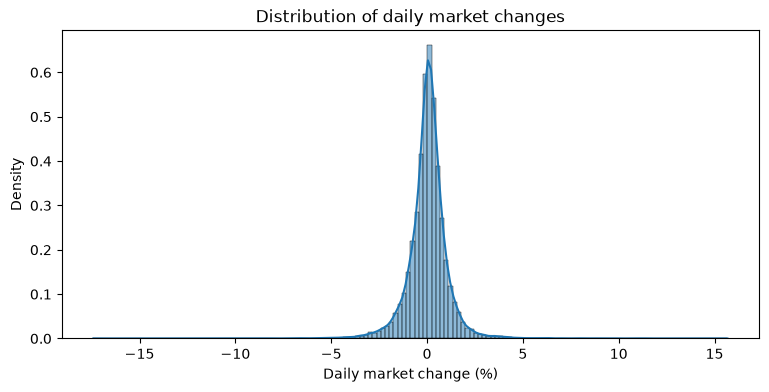

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

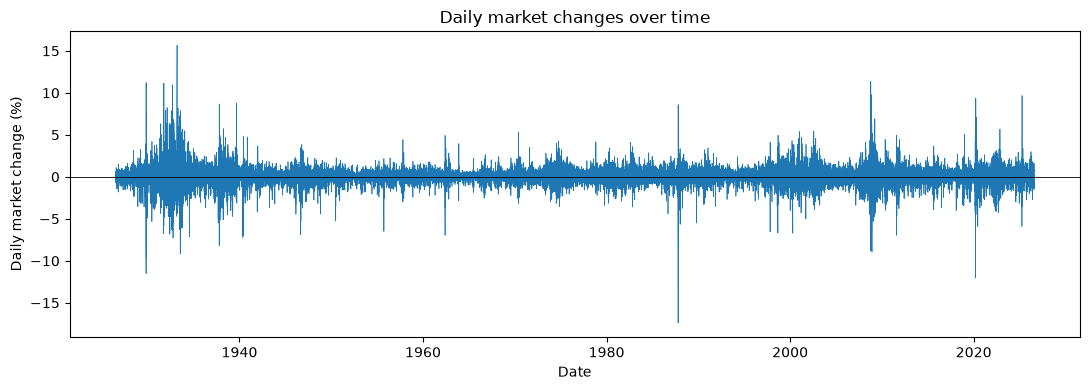

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [6]:
# Current and next-day values, and categories
df['r_tp1'] = df['market_return_pct'].shift(-1)
df['y_t']   = np.where(df['market_return_pct'] > 0, 'Up', 'Down')
df['y_tp1'] = df['r_tp1'].gt(0).map({False: 'Down', True: 'Up'}).where(df['r_tp1'].notna())
print(pd.crosstab(df['y_t'], df['y_tp1']))

y_tp1  Down    Up
y_t              
Down   5909  5999
Up     5999  8388


In [9]:
# Joint PMF and marginals
joint = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True, margins=True)
print(joint)


y_tp1      Down        Up       All
y_t                                
Down   0.224720  0.228142  0.452862
Up     0.228142  0.318996  0.547138
All    0.452862  0.547138  1.000000


y_tp1      Down        Up
y_t                      
Down   0.496221  0.503779
Up     0.416974  0.583026


<Axes: xlabel='y_tp1', ylabel='y_t'>

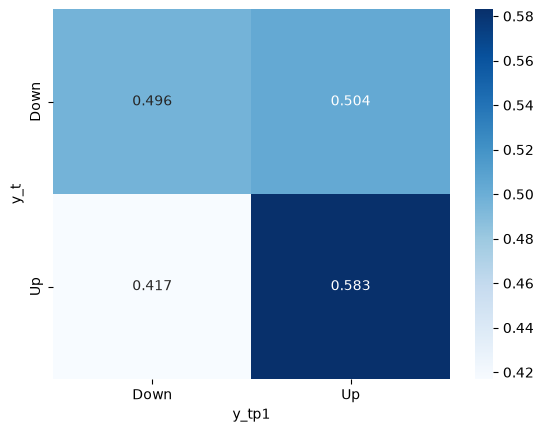

In [11]:
# Conditional PMF
cond = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')
print(cond)
sns.heatmap(cond, annot=True, fmt='.3f', cmap='Blues')

Are Up transitions more or less common than Down transitions?

The joint PMF table shows that up transitions are more common than down transitions. The marginal PMF of the next day's state is 0.547 for up vs 0.453 for down. Of the four joint outcomes, the table shows that up-up is the most common outcome (0.319) and down down is the least common (0.225).

Are you more likely to transition to an Up day from a Down day or from an Up day?

The conditional PMF table shows that you are more likely to transition to an up day from an up day as P(Up tommorow | Up today) = 0.583 wheras P(Up tommorow | Down today) = 0.504.

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [12]:
df['market_return_pct_bin'] = pd.cut(
    df['market_return_pct'],
    bins=[-np.inf, -1, -0.1, 0.1, 1, np.inf],
    labels=['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
)
df['y_t'] = df['market_return_pct_bin']
df['y_tp1'] = df['market_return_pct_bin'].shift(-1)
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)

df['y_t'].value_counts(sort=False)

y_t
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9785
Large gain    2859
Name: count, dtype: int64

How many days fall into each bin?

Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9785
Large gain    2859

The most common are small gain and small loss. The least common are large loss and large gain.

In [15]:
jointtab = pd.crosstab(df['y_t'], df['y_tp1'],
            normalize=True, margins=True)
jointtab

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


[Text(0.5, 1.0, 'Joint PMF')]

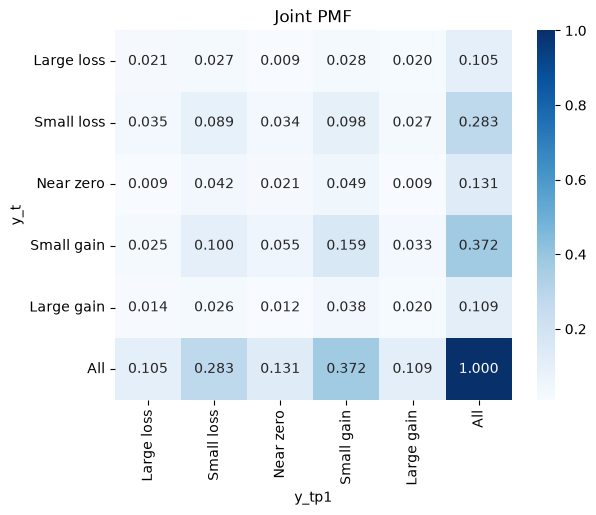

In [16]:
sns.heatmap(jointtab, annot=True, fmt='.3f', cmap='Blues').set(title='Joint PMF')

Which transitions are most likely?

The most likely transitions are small gain to small gain (15.9%) and then small gain to small loss (10%) and then small loss to small gain (9.8%) and then small loss to small loss (8.9%)

In [18]:
cond_pmf = pd.crosstab(df['y_t'], df['y_tp1'],
            normalize='index')
cond_pmf


y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


[Text(0.5, 1.0, 'Conditional PMF')]

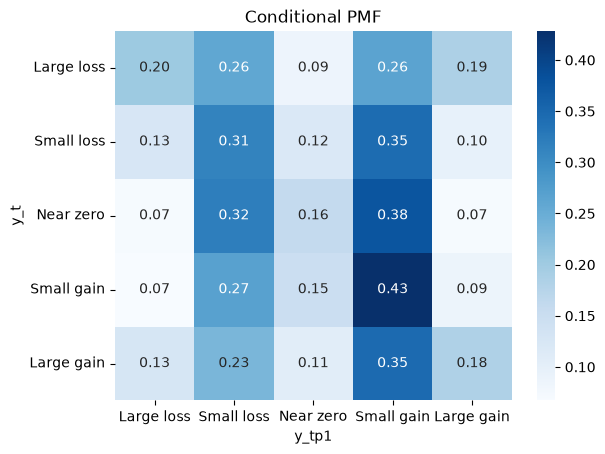

In [19]:
sns.heatmap(cond_pmf, annot=True, fmt='.2f', cmap='Blues').set(title='Conditional PMF')

What are the two most likely next states for each current state? How close is each row to uniform?

The two most likely next states for each current state are small gain and then small loss. Uniform is when every possible outcome has the same probability, so in this case since there are five, uniform would assign 20% probability to each. Large loss is the closest row to uniform, as after a large loss, almost anything has a similar probability of happening. Large gain is similar, although small gain is noticibly higher. Small gain is the least uniform followed by small loss as both have large probabilities of a small loss or a small gain and very small probabilities of a large loss or large gain.

In [20]:
#Conditional Expectation
df.groupby('y_t', observed=False)['market_return_pct_tp1'].describe()

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice.

Given the current state, the expected percent returns for tommorow are the values in the mean column in the table above. Its about -0.038 to -0.044% after losses and 0.11% to 0.16% after gains. The largest min value for tomorrow occurs after a large loss (-17.41%) and the largest max value for tommorow occurs after a large gain (15.67%), showing that both the worst day and best day occured after a large move. The range of movement gets narrower towards near zero. The highest standard deviation are also large loss (1.72) and large gain (1.38) which shows that those states have the most volatility. The pattern in the volatility shows that volatility is highest after large moves in either direction and lower when movement is smaller. It is also not completely symmetric either as losses both big and small are followed by more volatility (1.72 and 1.01) vs (1.38 and 0.83)

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [22]:
#21 bins based on quantile

df['y_t'] = pd.qcut(df['market_return_pct'], 21, labels=False)
df['y_tp1'] = df['y_t'].shift(-1)
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)

df['y_t'].value_counts().sort_index()

y_t
0     1255
1     1253
2     1286
3     1280
4     1230
5     1226
6     1371
7     1206
8     1198
9     1331
10    1210
11    1223
12    1294
13    1223
14    1310
15    1193
16    1211
17    1283
18    1225
19    1250
20    1238
Name: count, dtype: int64

[Text(0.5, 1.0, 'Joint PMF')]

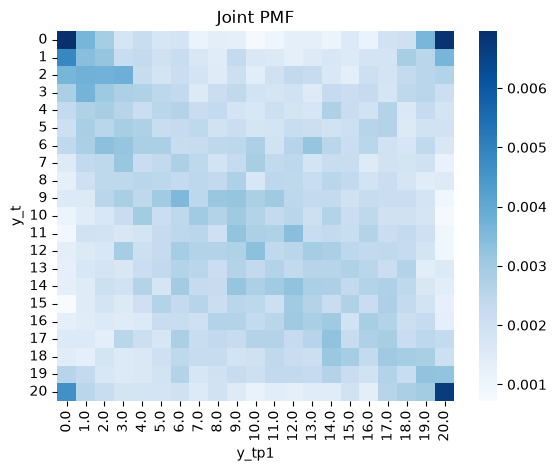

In [23]:
#Joint PMF 
jointtab = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)
sns.heatmap(jointtab, cmap='Blues').set(title='Joint PMF')


Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.

Most of the heatmap is light blue which shows that it is mostly unniform, although the four corners are much darker blue.

[Text(0.5, 1.0, 'Joint PMF minus uniform')]

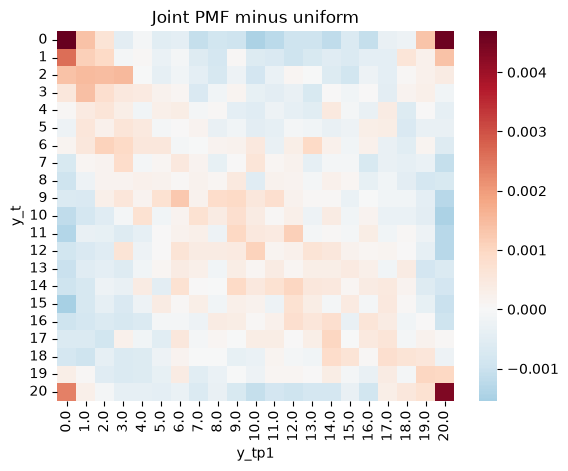

In [27]:
jointtab1 = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)
sns.heatmap(jointtab1 - 1/21**2, cmap='RdBu_r', center=0).set(title='Joint PMF minus uniform')

When subtracting 1/21^2, the red corners show an extreme day followed by another extreme day in either direction happens very frequently. Worst to best is almost as frequent as worst to worst and calm days tend to follow calm days as shown by the light red in the middle. The blue edges show that extreme to calm and calm to extreme is much less common. 

[Text(0.5, 1.0, 'Conditional PMF')]

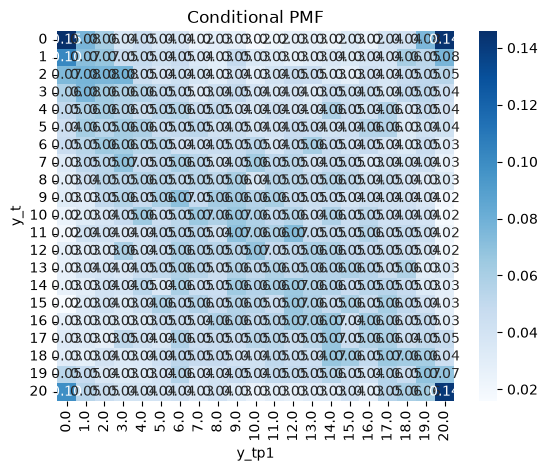

In [31]:
#Conditional PMF

cond_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')
sns.heatmap(cond_pmf, annot=True, fmt='.2f', cmap='Blues').set(title='Conditional PMF')

Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.

The conditional PMF heatmap looks almost the same as the joint PMF because each row holds about 1/21 of the days in each bin, so it is really just multiplying the joint by 21. Therefore the heatmaps show the same info. 

[Text(0.5, 1.0, 'Conditional PMF minus uniform')]

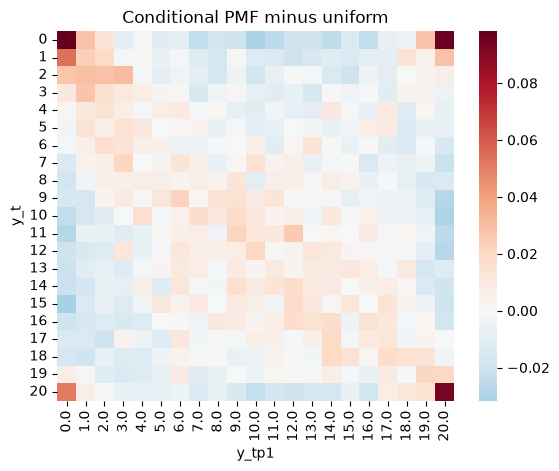

In [29]:
cond_pmf1 = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')
sns.heatmap(cond_pmf1 - 1/21, cmap='RdBu_r', center=0).set(title='Conditional PMF minus uniform')

When subtracting 1/21, this shows the same pattern as before but now it shows the deviations from a uniformly random transition, therfore a simlar pattern appears: the four corners are dark red, the center is warm, and the edges are lighter blue.

<Axes: title={'center': 'Next-day min / mean / max'}, xlabel="Today's bin", ylabel='Next-day return (%)'>

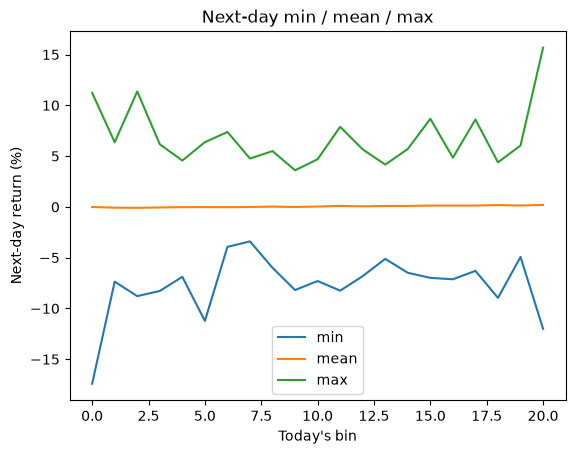

In [25]:
stats = df.groupby('y_t')['market_return_pct_tp1'].agg(['min', 'mean', 'max', 'std'])
stats[['min', 'mean', 'max']].plot(xlabel='Today\'s bin', 
                                   ylabel='Next-day return (%)',
                                   title='Next-day min / mean / max')

Do you see any obvious patterns? Explain. 

The mean apears to be at 0. The min and max show the most extreme movement towards the ends. This is because Bin 0 and bin 20 are followed by the largest drops/gains which reflects the volatility clustering pattern we've seen before. The range is narrowest in the middle bins. 

<Axes: title={'center': "Next-day volatility by today's bin"}, xlabel="Today's bin", ylabel='Next-day std (%)'>

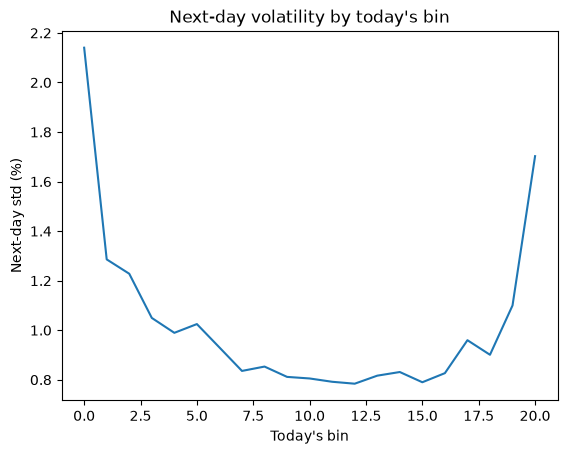

In [26]:
stats['std'].plot(xlabel='Today\'s bin', 
                  ylabel='Next-day std (%)',
                  title='Next-day volatility by today\'s bin')


Do you see any obvious patterns? Explain.

The standard deviation plot shows a U shape that displays the same pattern of volatility clustering. The most volatile movement predicts more volatile movement. The left side of the U is higher than the right, showing a similar pattern as before that large drops cause even more market volatility. 

How easy is it to predict the market?

Not very, because predicting the direction of the market is very hard. As shown in the conditional probability table the largest probabilities are all below 20%, which isn't very good if we are trying to make an accurate prediction. The mean being close to zero also does not give us a good indicator. It is easier to predict the volatility of the next movement in the market, but not direction, as a large drop is likely to be followed by a large movement, but it is almost equally likely to be a large drop or gain. 

Claude was used to help me with coding syntax when creating some of the tables and graphs throughout this lab.